# this code is from the documentation https://scikit-learn.org/stable/auto_examples/model_selection/plot_det.html

ROC curves feature true positive rate (TPR) on the Y axis, and false positive rate (FPR) on the X axis. 
This means that the top left corner of the plot is the “ideal” point - a FPR of zero, and a TPR of one.

In [1]:
from sklearn.datasets import make_classification 
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
import numpy as np

In [2]:


X, y = make_classification(  # Generates a random n-class classification problem.
    n_samples=1_000,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    random_state=1,
    n_clusters_per_class=1,
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

classifiers = {
    "Random Forest": RandomForestClassifier(
        max_depth=5, n_estimators=10, max_features=1, random_state=0
    ),
    "Non-informative baseline": DummyClassifier(), # makes constant predictions, independent of the input features in X, making it a non-informative classifier.
}

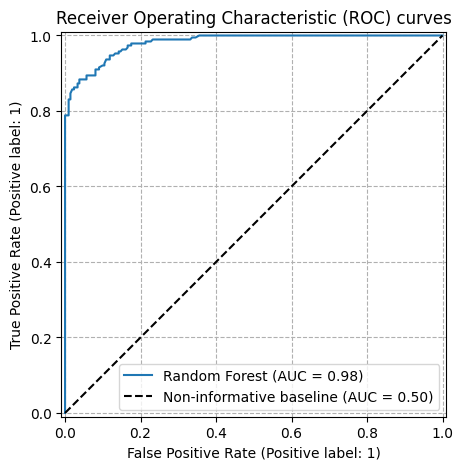

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

fig, ax= plt.subplots(1, 1, figsize=(11, 5))
ax.set_title("Receiver Operating Characteristic (ROC) curves")
ax.grid(linestyle="--")

for name, clf in classifiers.items():
    (color, linestyle) = (
        ("black", "--") if name == "Non-informative baseline" else (None, None)
    )
    clf.fit(X_train, y_train)
    RocCurveDisplay.from_estimator(
        clf,
        X_test,
        y_test,
        ax=ax,
        name=name,
        curve_kwargs=dict(color=color, linestyle=linestyle),
    )
plt.legend()
plt.show()

This example presents how to estimate and visualize the variance of the Receiver Operating Characteristic (ROC) metric using cross-validation.

ROC curves typically feature true positive rate (TPR) on the Y axis, and false positive rate (FPR) on the X axis. This means that the top left corner of the plot is the “ideal” point - a FPR of zero, and a TPR of one. This is not very realistic, but it does mean that a larger Area Under the Curve (AUC) is usually better. The “steepness” of ROC curves is also important, since it is ideal to maximize the TPR while minimizing the FPR.

This example shows the ROC response of different datasets, created from K-fold cross-validation. Taking all of these curves, it is possible to calculate the mean AUC, and see the variance of the curve when the training set is split into different subsets. This roughly shows how the classifier output is affected by changes in the training data, and how different the splits generated by K-fold cross-validation are from one another.

Code is from: https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc_crossval.html#sphx-glr-auto-examples-model-selection-plot-roc-crossval-py


In [14]:
iris = load_iris()
target_names = iris.target_names
X, y = iris.data, iris.target
X, y = X[y != 2], y[y != 2]
n_samples, n_features = X.shape

In [15]:
# We also add noisy features to make the problem harder.

random_state = np.random.RandomState(0)
X = np.concatenate([X, random_state.randn(n_samples, 200 * n_features)], axis=1)

Here we run cross_validate on a LogisticRegression classifier, then use the computed cross-validation results to plot the ROC curves fold-wise. Notice that the baseline to define the chance level (dashed ROC curve) is a classifier that would always predict the most frequent class.

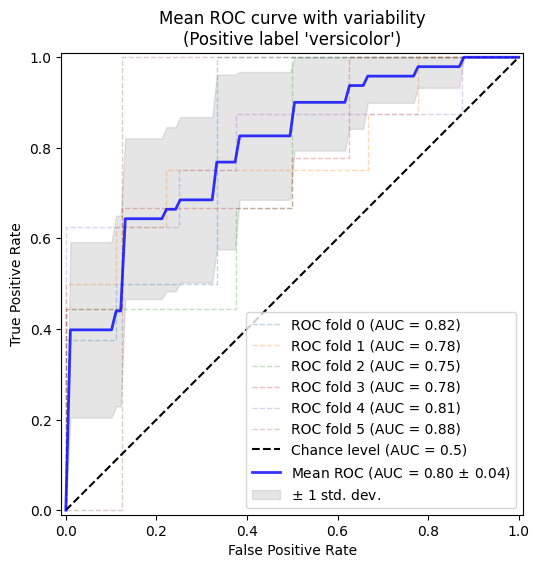

In [16]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, auc
from sklearn.model_selection import StratifiedKFold, cross_validate

n_splits = 6
cv = StratifiedKFold(n_splits=n_splits)
classifier = LogisticRegression(random_state=random_state).fit(X, y)
cv_results = cross_validate(
    classifier, X, y, cv=cv, return_estimator=True, return_indices=True
)

prop_cycle = plt.rcParams["axes.prop_cycle"]
colors = prop_cycle.by_key()["color"]
curve_kwargs_list = [
    dict(alpha=0.3, lw=1, color=colors[fold % len(colors)]) for fold in range(n_splits)
]
names = [f"ROC fold {idx}" for idx in range(n_splits)]

mean_fpr = np.linspace(0, 1, 100)
interp_tprs = []

_, ax = plt.subplots(figsize=(6, 6))
viz = RocCurveDisplay.from_cv_results(
    cv_results,
    X,
    y,
    ax=ax,
    name=names,
    curve_kwargs=curve_kwargs_list,
    plot_chance_level=True,
)

for idx in range(n_splits):
    interp_tpr = np.interp(mean_fpr, viz.fpr[idx], viz.tpr[idx])
    interp_tpr[0] = 0.0
    interp_tprs.append(interp_tpr)

mean_tpr = np.mean(interp_tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(viz.roc_auc)

ax.plot(
    mean_fpr,
    mean_tpr,
    color="b",
    label=r"Mean ROC (AUC = %0.2f $\pm$ %0.2f)" % (mean_auc, std_auc),
    lw=2,
    alpha=0.8,
)

std_tpr = np.std(interp_tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax.fill_between(
    mean_fpr,
    tprs_lower,
    tprs_upper,
    color="grey",
    alpha=0.2,
    label=r"$\pm$ 1 std. dev.",
)

ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title=f"Mean ROC curve with variability\n(Positive label '{target_names[1]}')",
)
ax.legend(loc="lower right")
plt.show()

Your turn!
The noisy features were added to make it harder to predict the classification. Run the iris classification again, but this time cut the amount of noise in half. Warning: the noise is being concatenated to the original data. If you run the concatenation command again with a lower value, you are adding MORE noise to the data set, not LESS noise! Instead of overwriting the code above, please copy-paste into new codeboxes below all the commands you need to do this part. 

In [17]:
#your code here
iris = load_iris()
target_names = iris.target_names
X_lessnoise, y = iris.data, iris.target
X_lessnoise, y = X_lessnoise[y != 2], y[y != 2]
n_samples, n_features = X_lessnoise.shape
random_state = np.random.RandomState(0)
X_lessnoise = np.concatenate([X_lessnoise, random_state.randn(n_samples, 100 * n_features)], axis=1)

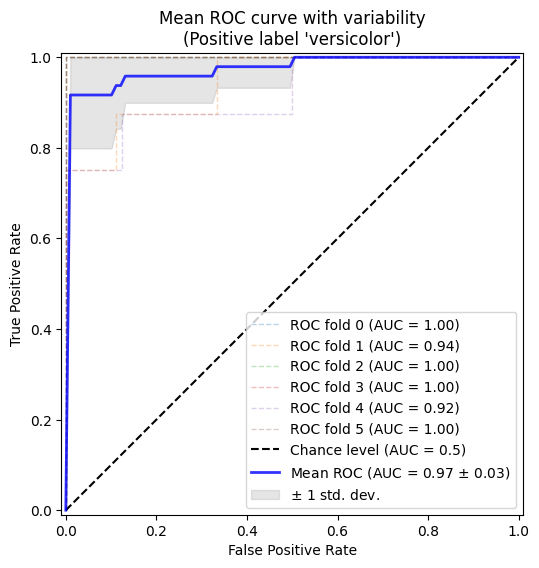

In [18]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, auc
from sklearn.model_selection import StratifiedKFold, cross_validate

n_splits = 6
cv = StratifiedKFold(n_splits=n_splits)
classifier = LogisticRegression(random_state=random_state).fit(X_lessnoise, y)
cv_results = cross_validate(
    classifier, X_lessnoise, y, cv=cv, return_estimator=True, return_indices=True
)

prop_cycle = plt.rcParams["axes.prop_cycle"]
colors = prop_cycle.by_key()["color"]
curve_kwargs_list = [
    dict(alpha=0.3, lw=1, color=colors[fold % len(colors)]) for fold in range(n_splits)
]
names = [f"ROC fold {idx}" for idx in range(n_splits)]

mean_fpr = np.linspace(0, 1, 100)
interp_tprs = []

_, ax = plt.subplots(figsize=(6, 6))
viz = RocCurveDisplay.from_cv_results(
    cv_results,
    X_lessnoise,
    y,
    ax=ax,
    name=names,
    curve_kwargs=curve_kwargs_list,
    plot_chance_level=True,
)

for idx in range(n_splits):
    interp_tpr = np.interp(mean_fpr, viz.fpr[idx], viz.tpr[idx])
    interp_tpr[0] = 0.0
    interp_tprs.append(interp_tpr)

mean_tpr = np.mean(interp_tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(viz.roc_auc)

ax.plot(
    mean_fpr,
    mean_tpr,
    color="b",
    label=r"Mean ROC (AUC = %0.2f $\pm$ %0.2f)" % (mean_auc, std_auc),
    lw=2,
    alpha=0.8,
)

std_tpr = np.std(interp_tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax.fill_between(
    mean_fpr,
    tprs_lower,
    tprs_upper,
    color="grey",
    alpha=0.2,
    label=r"$\pm$ 1 std. dev.",
)

ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title=f"Mean ROC curve with variability\n(Positive label '{target_names[1]}')",
)
ax.legend(loc="lower right")
plt.show()

Then try it again with no noise. Before you start, predict what the ROC curve should look like.  Hint: these two classes of flowers can be perfectly separated based on the features. 

In [19]:
#your code here
#your code here
iris = load_iris()
target_names = iris.target_names
X_nonoise, y = iris.data, iris.target
X_nonoise, y = X_nonoise[y != 2], y[y != 2]
n_samples, n_features = X_nonoise.shape
random_state = np.random.RandomState(0)
X_nonoise = np.concatenate([X_nonoise, random_state.randn(n_samples, 0 * n_features)], axis=1)

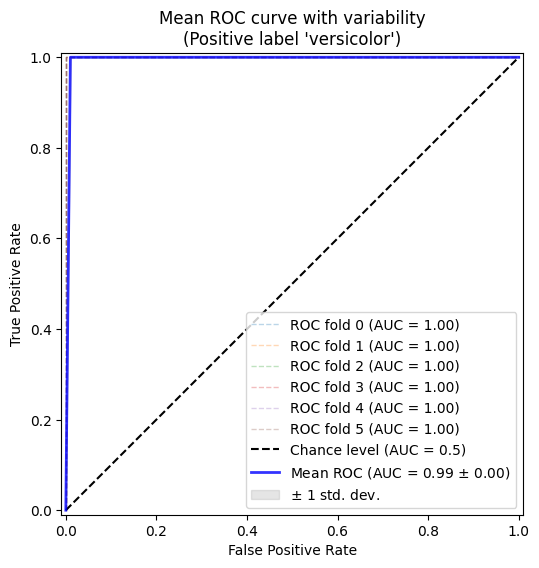

In [20]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, auc
from sklearn.model_selection import StratifiedKFold, cross_validate

n_splits = 6
cv = StratifiedKFold(n_splits=n_splits)
classifier = LogisticRegression(random_state=random_state).fit(X_nonoise, y)
cv_results = cross_validate(
    classifier, X_nonoise, y, cv=cv, return_estimator=True, return_indices=True
)

prop_cycle = plt.rcParams["axes.prop_cycle"]
colors = prop_cycle.by_key()["color"]
curve_kwargs_list = [
    dict(alpha=0.3, lw=1, color=colors[fold % len(colors)]) for fold in range(n_splits)
]
names = [f"ROC fold {idx}" for idx in range(n_splits)]

mean_fpr = np.linspace(0, 1, 100)
interp_tprs = []

_, ax = plt.subplots(figsize=(6, 6))
viz = RocCurveDisplay.from_cv_results(
    cv_results,
    X_nonoise,
    y,
    ax=ax,
    name=names,
    curve_kwargs=curve_kwargs_list,
    plot_chance_level=True,
)

for idx in range(n_splits):
    interp_tpr = np.interp(mean_fpr, viz.fpr[idx], viz.tpr[idx])
    interp_tpr[0] = 0.0
    interp_tprs.append(interp_tpr)

mean_tpr = np.mean(interp_tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(viz.roc_auc)

ax.plot(
    mean_fpr,
    mean_tpr,
    color="b",
    label=r"Mean ROC (AUC = %0.2f $\pm$ %0.2f)" % (mean_auc, std_auc),
    lw=2,
    alpha=0.8,
)

std_tpr = np.std(interp_tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax.fill_between(
    mean_fpr,
    tprs_lower,
    tprs_upper,
    color="grey",
    alpha=0.2,
    label=r"$\pm$ 1 std. dev.",
)

ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title=f"Mean ROC curve with variability\n(Positive label '{target_names[1]}')",
)
ax.legend(loc="lower right")
plt.show()

With no added noise, it is predicted that the model is perfectly accurate, meaning the ROC will be a line up at 0 all the way to 1 and then straight across at TPR=1 (right angle). Without added noise, the models created are all perfectly able to distinguish between the flowers, this is also shown in the reducted noise ROC by how the graph got closer to perfect as the noise decreased. This prediction was correct,  the shape that the ROC ended up being was a right angle.